Oefening 1: Exploratie

In [1]:
import pandas as pd
import json
import numpy as np

In [2]:
movies_df_raw = pd.read_csv('../../data/movies.csv') # Adjust path to the data folder
movies_df = movies_df_raw.assign(
                                release_date = pd.col('release_date').astype('datetime64[ns]'),
                                 genres = pd.col('genres').map(lambda s: json.loads(s.replace("'", '"')))
)

Oefening 1.1: Gebruik df.sample(), df.describe() en df.corr(numeric_only = True) om een eerste indruk van de dataset te krijgen. Wat zijn je observaties? Zijn er kolommen met ouliers, of met hele brede staarten (wat kunnen we daar mee doen bij het plotten / verbanden bekijken?)?

In [3]:
movies_df.sample(5, random_state = 42)

,movie_id,title,release_date,overview,tagline,original_language,original_title,budget,revenue,runtime,vote_average,vote_count,genres
7515,42090,After the Rehearsal,1984-04-09,"Rational, exacting, and self-controlled theate...",NaN,sv,Efter repetitionen,NaN,NaN,70.0,6.3,9,[Drama]
3673,12599,Pokémon: The Movie 2000,1999-07-17,Ash Ketchum must put his skill to the test whe...,One Person Can Make All The Difference!,ja,劇場版ポケットモンスター 幻のポケモン ルギア爆誕,30000000.0,133949270.0,84.0,6.4,201,"[Adventure, Fantasy, Animation, Science Fictio..."
29632,148431,"Ringo, It's Massacre Time",1970-08-02,"Ringo comes to a Mexican village, searching fo...",NaN,it,Giunse Ringo e... fu tempo di massacro,NaN,NaN,80.0,0.0,0,[Western]
20817,77234,The Numbers Station,2013-04-18,When the moral values of a longtime wetwork bl...,The code has never been compromised. Until now.,en,The Numbers Station,10000000.0,NaN,90.0,5.3,223,"[Action, Thriller]"
21938,187022,A Touch of Sin,2013-10-04,Four independent stories set in modern China a...,NaN,zh,天注定,NaN,154120.0,133.0,7.3,83,[Drama]


In [4]:
movies_df.describe()

,movie_id,release_date,budget,revenue,runtime,vote_average,vote_count
count,45370.000000,45370,8.884000e+03,7.407000e+03,45124.000000,45370.000000,45370.000000
mean,108009.170311,1992-05-14 10:24:01.269561344,2.161511e+07,6.879668e+07,94.191871,5.624814,110.109389
min,2.000000,1874-12-09 00:00:00,1.000000e+00,1.000000e+00,0.000000,0.000000,0.000000
25%,26382.000000,1978-10-05 06:00:00,2.000000e+06,2.400000e+06,85.000000,5.000000,3.000000
50%,59852.500000,2001-08-29 12:00:00,8.000000e+06,1.682954e+07,95.000000,6.000000,10.000000
75%,156388.750000,2010-12-16 00:00:00,2.500000e+07,6.725414e+07,107.000000,6.800000,34.000000
max,469172.000000,2017-12-31 00:00:00,3.800000e+08,2.787965e+09,1256.000000,10.000000,14075.000000
std,112153.877548,NaN,3.431920e+07,1.464280e+08,38.330753,1.914457,491.774060


In [5]:
movies_df.corr(numeric_only = True)

,movie_id,budget,revenue,runtime,vote_average,vote_count
movie_id,1.000000,-0.085131,-0.021925,-0.119243,-0.164923,-0.064472
budget,-0.085131,1.000000,0.730271,0.223364,0.094338,0.619864
revenue,-0.021925,0.730271,1.000000,0.202575,0.149390,0.781782
runtime,-0.119243,0.223364,0.202575,1.000000,0.156087,0.113502
vote_average,-0.164923,0.094338,0.149390,0.156087,1.000000,0.123594
vote_count,-0.064472,0.619864,0.781782,0.113502,0.123594,1.000000


Oefening 1.2: Gebruik df.isnull().mean(). Zijn er kolommen die veel nullwaarden bevatten? Zijn er waarden die volgens .isnull niet null zijn, maar die we eigenlijk wel als ontbrekend zouden moeten beschouwen? Hint: Zoek op 'Last Summer in the Hamptons' in de dataset en op Imdb. Kun je een patroon vinden in de verdeling van deze nulls? Wat zijn je conclusies voor de bruikbaarheid van deze set?

In [6]:
movies_df.isnull().mean()

movie_id             0.000000
title                0.000000
release_date         0.000000
overview             0.020741
tagline              0.550408
original_language    0.000242
original_title       0.000000
budget               0.804188
revenue              0.836742
runtime              0.005422
vote_average         0.000000
vote_count           0.000000
genres               0.000000
dtype: float64

In [7]:
movies_df_extended_null = movies_df.assign(
                                        vote_count = pd.col('vote_count').replace({0: np.nan}),
                                        vote_average = pd.col('vote_average').replace({0: np.nan}), # 0 is niet mogelijk om te geven op imdb, probeer maar. Historisch was dat wellicht mogelijk wel het geval.
                                        genres = pd.col('genres').map(lambda x: np.nan if x == [] else x)
                                        )

In [8]:
movies_df_extended_null.isnull().mean()

movie_id             0.000000
title                0.000000
release_date         0.000000
overview             0.020741
tagline              0.550408
original_language    0.000242
original_title       0.000000
budget               0.804188
revenue              0.836742
runtime              0.005422
vote_average         0.064823
vote_count           0.062773
genres               0.052546
dtype: float64

In [9]:
movies_df_extended_null[['vote_average', 'vote_count']].isnull().corr()

,vote_average,vote_count
vote_average,1.000000,0.982985
vote_count,0.982985,1.000000


In [10]:
(
    movies_df_extended_null
    .assign(revenue_is_null = pd.col('revenue').isnull())
    [['release_date', 'vote_count','revenue_is_null']]
    .corr()
)

,release_date,vote_count,revenue_is_null
release_date,1.000000,0.108315,-0.143026
vote_count,0.108315,1.000000,-0.401460
revenue_is_null,-0.143026,-0.401460,1.000000


In [11]:
movies_df_extended_null[(pd.col('release_date') >= '2000-01-01') & (pd.col('vote_count') > 1000)].isnull().mean()

movie_id             0.000000
title                0.000000
release_date         0.000000
overview             0.000000
tagline              0.023569
original_language    0.000000
original_title       0.000000
budget               0.010101
revenue              0.012346
runtime              0.000000
vote_average         0.000000
vote_count           0.000000
genres               0.000000
dtype: float64

Oefening 1.3: Hoeveel films komen er per taal (original language) voor? Hoe worden films aan de IMDb toegevoegd? In hoeverre denk je dat getallen die we obv. de IMDb berekenen representatief zijn?

In [12]:
(
    movies_df
    .groupby('original_language', as_index = False)
    .agg(number_of_movies = ('movie_id', 'count'))
    .sort_values(by = 'number_of_movies', ascending=False)
)

,original_language,number_of_movies
17,en,32196
24,fr,2437
34,it,1528
36,ja,1349
15,de,1078
...,...,...
63,qu,1
71,sm,1
77,tg,1
83,uz,1


Films worden door gebruikersinzending toegevoegd: https://help.imdb.com/article/contribution/titles/adding-a-new-title/GNXTSSVTJTFCRZGN#

Oefening 2: Visualisatie

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# Focus op Engelstalige en recente films omdat de set daarvoor representatiever is:

movies_in_scope = (movies_df.loc[
                                    (pd.col('release_date') >= '2000-01-01')
                                    & (pd.col('original_language') == 'en')
                                    ]
)

Oefening 2.1: Recreëer deze plot met (enkel) matplotlib.

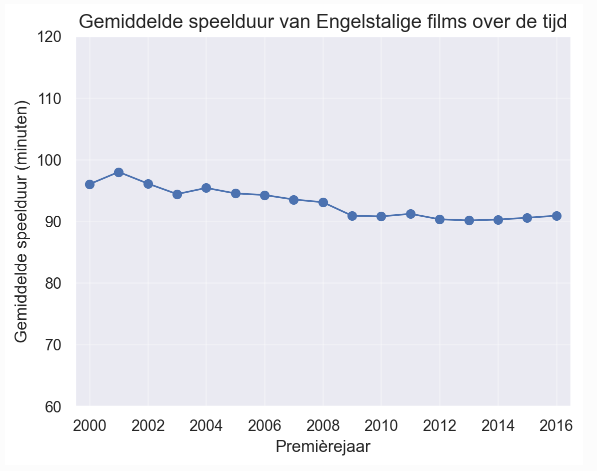

In [15]:
sns.set_theme(style="darkgrid") 

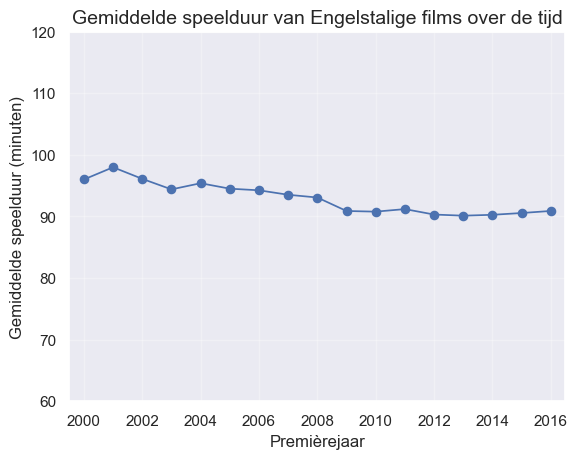

In [16]:
yearly_avg = movies_in_scope.loc[
    (pd.col('release_date') <= '2016-12-31') # Vulling van de datasets voor films uit 2017 is nog niet compleet
].assign(release_year = pd.col('release_date').dt.year).groupby('release_year', as_index = False).agg(average_runtime = ('runtime', 'mean')) 

fig, ax = plt.subplots()
ax.plot(
    yearly_avg['release_year'], 
    yearly_avg['average_runtime'],       
    linestyle='-',       
    linewidth=1.25,     
    color='#4C72B0'     
)
ax.scatter(
    yearly_avg['release_year'], 
    yearly_avg['average_runtime'],      
    s =35,          
    color='#4C72B0'     
)
ax.set_ylim(60, 120)
ax.set_xlim(1999.5, 2016.5)
ax.set_title('Gemiddelde speelduur van Engelstalige films over de tijd', fontsize=14)
ax.set_xlabel('Premièrejaar', fontsize=12)
ax.set_ylabel('Gemiddelde speelduur (minuten)', fontsize=12)
ax.grid(alpha=0.3)
plt.show()

Exercise 2.2:  Recreëer deze plot met sns.violinplot. Heb je interessante observaties?

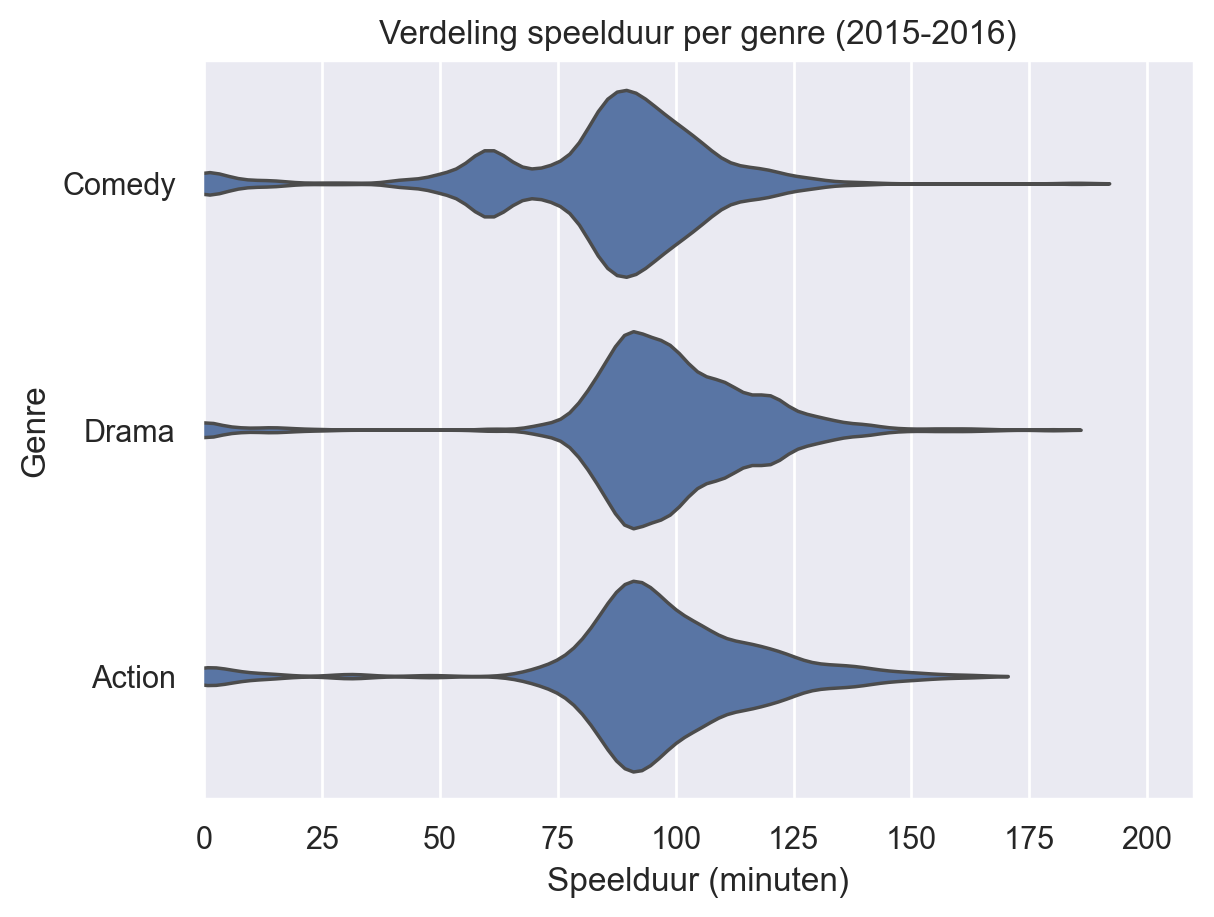

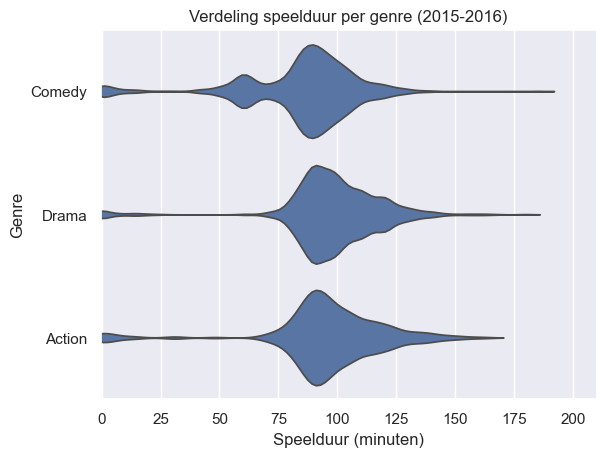

In [17]:
upper_runtime_limit = 210 # Focus only on movies up to 3 1/2 hours

movies_in_timeframe = movies_in_scope.loc[
    (pd.col("release_date") >= "2015-01-02")
    & (pd.col("release_date") <= "2016-12-30")
    & (pd.col("runtime") <= upper_runtime_limit) 
]

movies_with_relevant_genres = movies_in_timeframe.explode("genres").loc[pd.col('genres').isin(['Action', 'Comedy', 'Drama'])]

fig, ax = plt.subplots()

sns.violinplot(
    data=movies_with_relevant_genres,
    x="runtime",
    y="genres",
    order=["Comedy", "Drama", "Action"],
    inner=None,
    bw_adjust=0.5,
    ax = ax
    )

ax.set_xlim(-0.5, upper_runtime_limit)
ax.set_xlabel("Speelduur (minuten)")
ax.set_ylabel("Genre")
ax.set_title("Verdeling speelduur per genre (2015-2016)")

plt.show()

Exercise 2.3: Recreëer deze plot met sns.jointplot. (Hint: gebruik graph.ax_joint om de axes van de subplots tegelijkertijd aan te spreken). Welke conclusies trek je uit de plot?

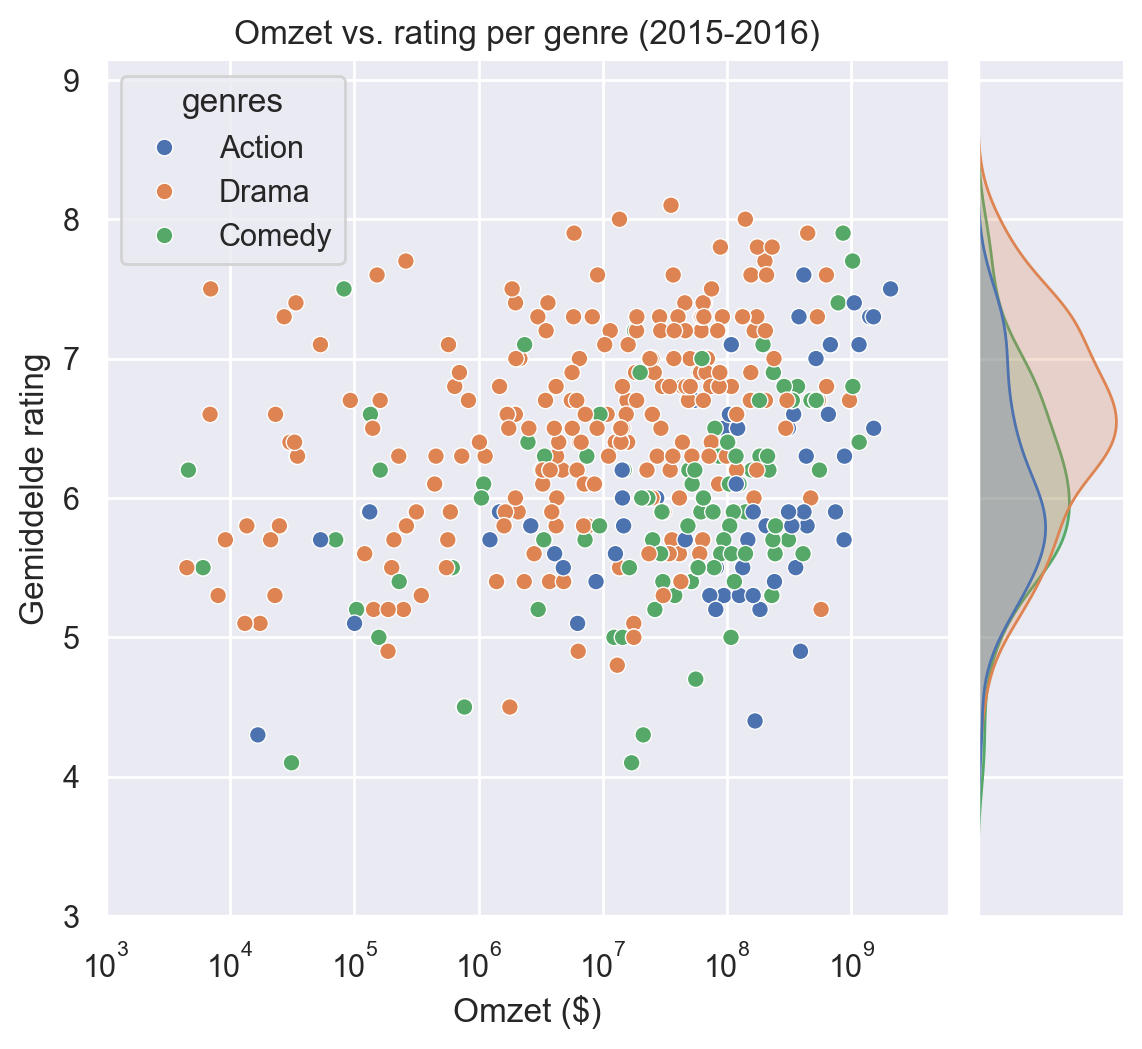

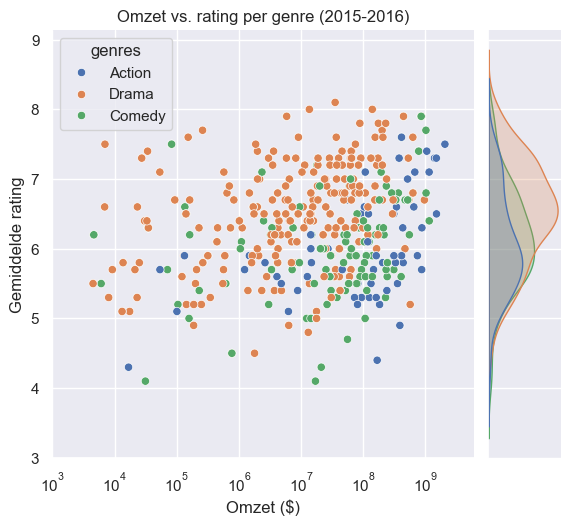

In [18]:
g = sns.jointplot(data=movies_with_relevant_genres.dropna(subset = ['revenue']), x="revenue", y="vote_average", hue="genres")
g.ax_marg_x.remove()
g.ax_joint.set_xscale('log')
g.ax_joint.set_xlim(left = 1000)
g.ax_joint.set_xlabel('Omzet ($)')
g.ax_joint.set_ylabel('Gemiddelde rating')
g.ax_joint.set_title('Omzet vs. rating per genre (2015-2016)')

plt.show()

Oefening 3.1: Draai deze code, scroll om in te zoomen en houd je muis over de films rechtsboven. Herken je ze? Is de informatie die er bij staat nuttig? Gebruik vervolgens chart.save('filename.svg') om de chart als svg op te slaan. Zoom in. Wat valt je op?

In [19]:
import altair as alt

In [20]:
movies_with_relevant_genres =  movies_in_scope.loc[
    (pd.col("release_date") >= "2015-01-02")
    & (pd.col("release_date") <= "2016-12-30")].dropna(subset = ['revenue']).explode('genres').loc[
        pd.col("genres").isin(["Action", "Drama", "Comedy"])
    ]

# Rename columns for altair plot
movies_df_renamed = movies_with_relevant_genres.rename(
        columns = {"vote_average": "Gemiddelde rating", "title": "Titel", "vote_count": "Aantal stemmen", "revenue": "Omzet", "genres": "Genre"}
)

chart = (
        alt.Chart(movies_df_renamed)
            .mark_circle(size=60)
            .encode(
            x=alt.X('Omzet',scale=alt.Scale(type='log', domain=[1_000, 10_000_000_000]),
                    axis=alt.Axis(
                values=[1_000, 100_000, 10_000_000, 1_000_000_000],
                format="$.0e"
            )
                        ),
            y='Gemiddelde rating',
            color='Genre',
            tooltip = ['Titel', 'Omzet', 'Gemiddelde rating', 'Aantal stemmen', 'Genre']
            )
        )

chart = chart.add_params(
     alt.selection_interval(bind='scales')
)

chart

alt.Chart(...)

In [21]:
chart.save("my_file.svg")

Oefening 3.2, vrije opdracht: Welke hypothesen wil je graag toetsen over deze dataset? Hoe wil je dat visualizeren? Breng deze ideeën in de praktijk met wat je deze cursus geleerd hebt! Kies zelf wat voor visualisatie je wilt maken, en of je dit met matplotlib, seaborn, altair (of great tables, ...) wilt doen.